In [1]:
import os
from pathlib import Path
import cv2
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import random

In [2]:
# Chemin du projet
PROJECT_ROOT = Path.cwd().parent

# Si le notebook est exécuté depuis le dossier notebooks
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

# Chemin du Dataset
DATASET_ROOT = PROJECT_ROOT / "Data" / "detection" / "raw"

print("Dataset existe :", DATASET_ROOT.exists())
print("Chemin :", DATASET_ROOT)

Dataset existe : True
Chemin : c:\Users\ajbba\Desktop\YOUCODE-IA\Diagnostic_tumeurs\Data\detection\raw


In [3]:
for root, dirs, files in os.walk(DATASET_ROOT):

    level = len(Path(root).relative_to(DATASET_ROOT).parts)

    if level > 3:
        continue

    indent = "    " * level

    print(f"{indent}{Path(root).name}/")

    for file in files[:3]:
        print(f"{indent}    {file}")

raw/
    Train/
        Glioma/
            images/
                gg (1).jpg
                gg (103).jpg
                gg (104).jpg
            labels/
                gg (1).txt
                gg (103).txt
                gg (104).txt
        Meningioma/
            images/
                m (10).jpg
                m (101).jpg
                m (102).jpg
            labels/
                m (10).txt
                m (101).txt
                m (102).txt
        No Tumor/
            images/
                1.jpg
                3.jpg
                4.jpg
            labels/
                1.txt
                3.txt
                4.txt
        Pituitary/
            images/
                p (1).jpg
                p (10).jpg
                p (100).jpg
            labels/
                p (1).txt
                p (10).txt
                p (100).txt
    Val/
        Glioma/
            images/
                gg (10).jpg
                gg (131).jpg
                gg 

In [4]:
# Récupérer les images
image_paths = list(DATASET_ROOT.rglob("*.jpg"))

# Récupérer les fichiers labels
label_paths = list(DATASET_ROOT.rglob("*.txt"))

print("Nombre d'images :", len(image_paths))
print("Nombre de fichiers labels :", len(label_paths))

Nombre d'images : 5249
Nombre de fichiers labels : 5249


In [5]:
class_names = {
    0: "Glioma",
    1: "Meningioma",
    2: "No Tumor",
    3: "Pituitary"
}

print(class_names)

{0: 'Glioma', 1: 'Meningioma', 2: 'No Tumor', 3: 'Pituitary'}


In [6]:


for label_path in label_paths[:5]:

    print("Fichier :", label_path.name)

    with open(label_path, "r") as file:
        lines = file.readlines()

    for line in lines:
        print(line.strip())

    print("-" * 50)

Fichier : gg (1).txt
0 0.567383 0.519531 0.189453 0.148438
--------------------------------------------------
Fichier : gg (103).txt
0 0.414062 0.490234 0.140625 0.132812
--------------------------------------------------
Fichier : gg (104).txt
0 0.425781 0.486328 0.191406 0.164062
--------------------------------------------------
Fichier : gg (105).txt
0 0.423828 0.477539 0.187500 0.173828
--------------------------------------------------
Fichier : gg (106).txt
0 0.420898 0.463867 0.181641 0.150391
--------------------------------------------------


In [7]:


valid_labels = 0
invalid_labels = 0

for label_path in label_paths:

    with open(label_path, "r") as file:
        lines = file.readlines()

    for line in lines:

        values = line.strip().split()

        # Vérifier le nombre de valeurs
        if len(values) != 5:
            invalid_labels += 1
            continue

        class_id = int(values[0])
        x_center, y_center, width, height = map(float, values[1:])

        # Vérifier les coordonnées
        if (
            class_id in class_names
            and 0 <= x_center <= 1
            and 0 <= y_center <= 1
            and 0 < width <= 1
            and 0 < height <= 1
        ):
            valid_labels += 1

        else:
            invalid_labels += 1

print("Annotations valides :", valid_labels)
print("Annotations invalides :", invalid_labels)

Annotations valides : 5873
Annotations invalides : 0


In [8]:

image_stems = {path.stem for path in image_paths}
label_stems = {path.stem for path in label_paths}

# Images sans fichiers labels
images_without_labels = image_stems - label_stems

# Labels sans images correspondantes
labels_without_images = label_stems - image_stems

print("Images sans labels :", len(images_without_labels))
print("Labels sans images :", len(labels_without_images))

print("\nExemples d'images sans labels :")
print(list(images_without_labels)[:10])

print("\nExemples de labels sans images :")
print(list(labels_without_images)[:10])

Images sans labels : 2
Labels sans images : 2

Exemples d'images sans labels :
['image(55)', 'image(61)']

Exemples de labels sans images :
['image(53)', 'image(60)']


In [9]:
# %%
# Localiser les fichiers problématiques

print("=== Images sans labels ===")

for image_path in image_paths:
    if image_path.stem in images_without_labels:
        print(image_path)

print("\n=== Labels sans images ===")

for label_path in label_paths:
    if label_path.stem in labels_without_images:
        print(label_path)

=== Images sans labels ===
c:\Users\ajbba\Desktop\YOUCODE-IA\Diagnostic_tumeurs\Data\detection\raw\Val\No Tumor\images\image(55).jpg
c:\Users\ajbba\Desktop\YOUCODE-IA\Diagnostic_tumeurs\Data\detection\raw\Val\No Tumor\images\image(61).jpg

=== Labels sans images ===
c:\Users\ajbba\Desktop\YOUCODE-IA\Diagnostic_tumeurs\Data\detection\raw\Val\No Tumor\labels\image(53).txt
c:\Users\ajbba\Desktop\YOUCODE-IA\Diagnostic_tumeurs\Data\detection\raw\Val\No Tumor\labels\image(60).txt


In [10]:


orphan_labels = [
    label_path
    for label_path in label_paths
    if label_path.stem in labels_without_images
]

for label_path in orphan_labels:

    print("Fichier :", label_path.name)

    with open(label_path, "r") as file:
        content = file.read()

    print("Contenu :", repr(content))
    print("-" * 50)

Fichier : image(53).txt
Contenu : '2 0.506818 0.494545 0.913636 0.930909\n'
--------------------------------------------------
Fichier : image(60).txt
Contenu : '2 0.502119 0.514831 0.572034 0.682203\n'
--------------------------------------------------


In [11]:


orphan_images = [
    image_path
    for image_path in image_paths
    if image_path.stem in images_without_labels
]

for image_path in orphan_images:

    image = cv2.imread(str(image_path))

    print("Image :", image_path.name)
    print("Image chargée :", image is not None)

    if image is not None:
        print("Dimensions :", image.shape)

Image : image(55).jpg
Image chargée : True
Dimensions : (243, 236, 3)
Image : image(61).jpg
Image chargée : True
Dimensions : (234, 218, 3)


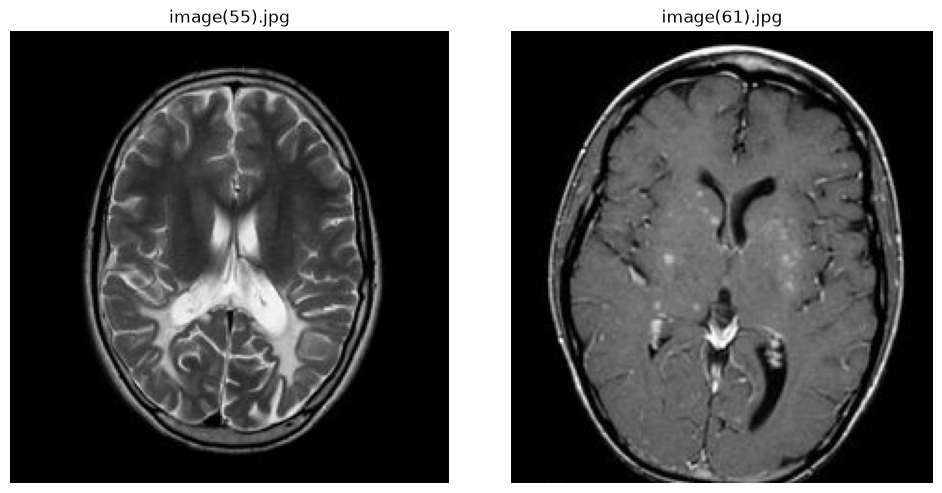

In [12]:


plt.figure(figsize=(10, 5))

for i, image_path in enumerate(orphan_images):

    image = cv2.imread(str(image_path))

    # Convertir BGR vers RGB
    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

    plt.subplot(1, 2, i + 1)
    plt.imshow(image)
    plt.title(image_path.name)
    plt.axis("off")

plt.tight_layout()
plt.show()

In [13]:


yaml_files = list(DATASET_ROOT.parent.rglob("*.yaml"))

for file in yaml_files:
    print(file)

c:\Users\ajbba\Desktop\YOUCODE-IA\Diagnostic_tumeurs\Data\detection\processed\yolo_dataset\data.yaml


In [14]:
from collections import Counter

class_distribution = Counter()

for label_path in label_paths:

    with open(label_path, "r") as file:

        for line in file:

            values = line.strip().split()

            if len(values) == 5:
                class_id = int(values[0])
                class_distribution[class_id] += 1

print("Distribution des classes :")

for class_id, count in sorted(class_distribution.items()):
    print(f"Class {class_id} ({class_names.get(class_id, 'Unknown')}) : {count}")

Distribution des classes :
Class 0 (Glioma) : 1502
Class 1 (Meningioma) : 1624
Class 2 (No Tumor) : 811
Class 3 (Pituitary) : 1936


In [15]:
# %%
# Rechercher les fichiers YAML

yaml_files = list(DATASET_ROOT.parent.rglob("*.yaml"))

print("Nombre de fichiers YAML :", len(yaml_files))

for file in yaml_files:
    print(file)

Nombre de fichiers YAML : 1
c:\Users\ajbba\Desktop\YOUCODE-IA\Diagnostic_tumeurs\Data\detection\processed\yolo_dataset\data.yaml


In [16]:
# %%
# Vérifier les classes présentes dans chaque dossier

for split in ["Train", "Val"]:

    print(f"\n===== {split} =====")

    for class_name in class_names.values():

        class_folder = DATASET_ROOT / split / class_name / "labels"

        if class_folder.exists():

            ids = set()

            for label_path in class_folder.glob("*.txt"):

                with open(label_path, "r") as file:

                    for line in file:

                        values = line.strip().split()

                        if len(values) == 5:
                            ids.add(int(values[0]))

            print(f"{class_name} : {sorted(ids)}")


===== Train =====
Glioma : [0, 1, 3]
Meningioma : [0, 1, 3]
No Tumor : [2]
Pituitary : [1, 3]

===== Val =====
Glioma : [0, 3]
Meningioma : [1, 3]
No Tumor : [2]
Pituitary : [3]


In [17]:
# %%
from collections import Counter

for split in ["Train", "Val"]:

    print(f"\n========== {split} ==========")

    for class_name in class_names.values():

        label_folder = DATASET_ROOT / split / class_name / "labels"

        distribution = Counter()

        if label_folder.exists():

            for label_path in label_folder.glob("*.txt"):

                with open(label_path, "r") as file:

                    for line in file:

                        values = line.strip().split()

                        if len(values) == 5:
                            class_id = int(values[0])
                            distribution[class_id] += 1

        print(f"\n{class_name} :")

        for class_id, count in sorted(distribution.items()):

            print(
                f"  Class {class_id} "
                f"({class_names[class_id]}) : {count}"
            )


========== Train ==========

Glioma :
  Class 0 (Glioma) : 1347
  Class 1 (Meningioma) : 3
  Class 3 (Pituitary) : 152

Meningioma :
  Class 0 (Glioma) : 2
  Class 1 (Meningioma) : 1478
  Class 3 (Pituitary) : 103

No Tumor :
  Class 2 (No Tumor) : 711

Pituitary :
  Class 1 (Meningioma) : 1
  Class 3 (Pituitary) : 1520

========== Val ==========

Glioma :
  Class 0 (Glioma) : 153
  Class 3 (Pituitary) : 12

Meningioma :
  Class 1 (Meningioma) : 142
  Class 3 (Pituitary) : 6

No Tumor :
  Class 2 (No Tumor) : 100

Pituitary :
  Class 3 (Pituitary) : 143


In [18]:
# %%
# Identifier les annotations incohérentes avec le dossier

for split in ["Train", "Val"]:

    print(f"\n========== {split} ==========")

    for class_name in class_names.values():

        label_folder = DATASET_ROOT / split / class_name / "labels"

        expected_class_id = {
            name: class_id
            for class_id, name in class_names.items()
        }[class_name]

        if not label_folder.exists():
            continue

        for label_path in label_folder.glob("*.txt"):

            with open(label_path, "r") as file:

                for line in file:

                    values = line.strip().split()

                    if len(values) == 5:

                        actual_class_id = int(values[0])

                        if actual_class_id != expected_class_id:

                            print(
                                f"Dossier: {class_name} | "
                                f"Fichier: {label_path.name} | "
                                f"Class ID: {actual_class_id} "
                                f"({class_names.get(actual_class_id, 'Unknown')})"
                            )


========== Train ==========
Dossier: Glioma | Fichier: gg (118).txt | Class ID: 3 (Pituitary)
Dossier: Glioma | Fichier: gg (129).txt | Class ID: 3 (Pituitary)
Dossier: Glioma | Fichier: gg (139).txt | Class ID: 3 (Pituitary)
Dossier: Glioma | Fichier: gg (143).txt | Class ID: 3 (Pituitary)
Dossier: Glioma | Fichier: gg (159).txt | Class ID: 3 (Pituitary)
Dossier: Glioma | Fichier: gg (160).txt | Class ID: 3 (Pituitary)
Dossier: Glioma | Fichier: gg (161).txt | Class ID: 3 (Pituitary)
Dossier: Glioma | Fichier: gg (164).txt | Class ID: 3 (Pituitary)
Dossier: Glioma | Fichier: gg (165).txt | Class ID: 3 (Pituitary)
Dossier: Glioma | Fichier: gg (166).txt | Class ID: 3 (Pituitary)
Dossier: Glioma | Fichier: gg (167).txt | Class ID: 3 (Pituitary)
Dossier: Glioma | Fichier: gg (169).txt | Class ID: 3 (Pituitary)
Dossier: Glioma | Fichier: gg (170).txt | Class ID: 3 (Pituitary)
Dossier: Glioma | Fichier: gg (171).txt | Class ID: 3 (Pituitary)
Dossier: Glioma | Fichier: gg (252).txt | Class

In [19]:
# %%
# Résumé des annotations différentes du dossier

from collections import Counter

mismatch_distribution = Counter()
mismatch_files = []

for split in ["Train", "Val"]:

    for class_name in class_names.values():

        label_folder = DATASET_ROOT / split / class_name / "labels"

        expected_class_id = {
            name: class_id
            for class_id, name in class_names.items()
        }[class_name]

        if not label_folder.exists():
            continue

        for label_path in label_folder.glob("*.txt"):

            with open(label_path, "r") as file:

                for line in file:

                    values = line.strip().split()

                    if len(values) == 5:

                        actual_class_id = int(values[0])

                        if actual_class_id != expected_class_id:

                            mismatch_distribution[
                                (split, class_name, actual_class_id)
                            ] += 1

                            mismatch_files.append(label_path)

print("Distribution des annotations différentes :\n")

for (split, folder, class_id), count in sorted(
    mismatch_distribution.items()
):

    print(
        f"{split} | Dossier : {folder} | "
        f"Class réelle : {class_names[class_id]} | "
        f"Nombre : {count}"
    )

print("\nNombre de fichiers concernés :",
      len(set(mismatch_files)))

Distribution des annotations différentes :

Train | Dossier : Glioma | Class réelle : Meningioma | Nombre : 3
Train | Dossier : Glioma | Class réelle : Pituitary | Nombre : 152
Train | Dossier : Meningioma | Class réelle : Glioma | Nombre : 2
Train | Dossier : Meningioma | Class réelle : Pituitary | Nombre : 103
Train | Dossier : Pituitary | Class réelle : Meningioma | Nombre : 1
Val | Dossier : Glioma | Class réelle : Pituitary | Nombre : 12
Val | Dossier : Meningioma | Class réelle : Pituitary | Nombre : 6

Nombre de fichiers concernés : 272


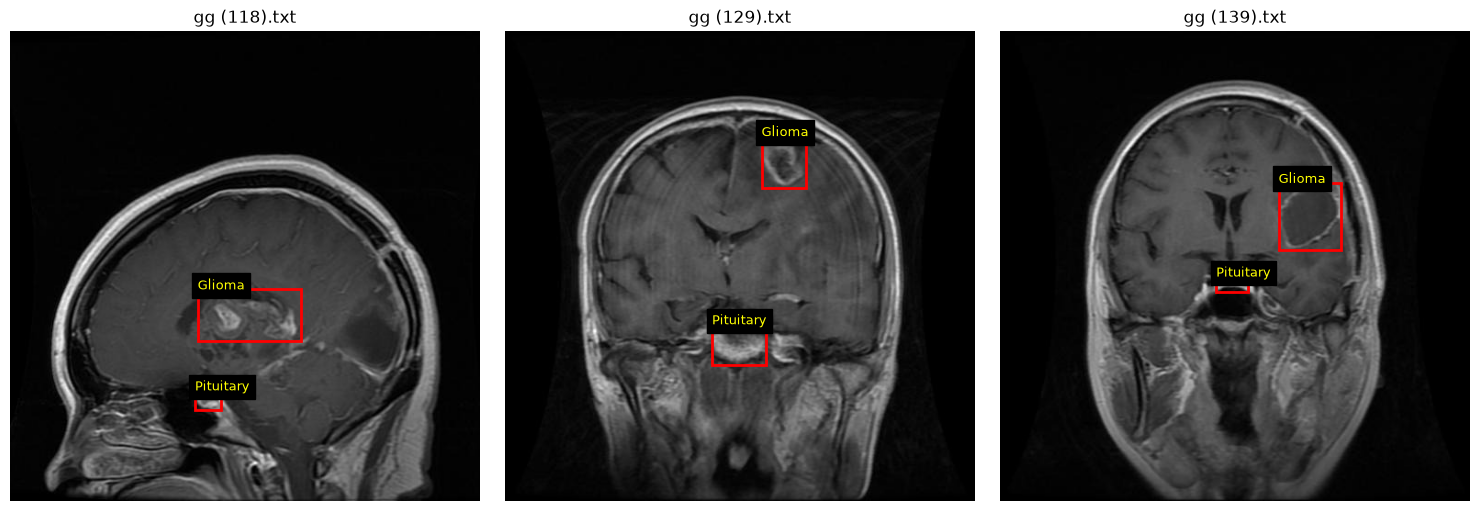

In [20]:
# %%
# Visualiser quelques annotations différentes du dossier

import matplotlib.pyplot as plt
import matplotlib.patches as patches
import cv2

# Choisir 3 fichiers différents
samples = list(dict.fromkeys(mismatch_files))[:3]

fig, axes = plt.subplots(
    1, len(samples),
    figsize=(15, 5)
)

if len(samples) == 1:
    axes = [axes]

for ax, label_path in zip(axes, samples):

    # Chercher l'image correspondante
    image_folder = label_path.parent.parent / "images"

    image_candidates = list(
        image_folder.glob(label_path.stem + ".*")
    )

    if not image_candidates:
        print("Image introuvable :", label_path.name)
        continue

    image_path = image_candidates[0]

    image = cv2.imread(str(image_path))
    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

    height, width, _ = image.shape

    ax.imshow(image)

    with open(label_path, "r") as file:

        for line in file:

            values = line.strip().split()

            if len(values) != 5:
                continue

            class_id = int(values[0])

            x_center, y_center, box_width, box_height = map(
                float, values[1:]
            )

            # Conversion des coordonnées normalisées en pixels
            x_center *= width
            y_center *= height
            box_width *= width
            box_height *= height

            x_min = x_center - box_width / 2
            y_min = y_center - box_height / 2

            rect = patches.Rectangle(
                (x_min, y_min),
                box_width,
                box_height,
                linewidth=2,
                edgecolor="red",
                facecolor="none"
            )

            ax.add_patch(rect)

            ax.text(
                x_min,
                y_min,
                class_names.get(class_id, "Unknown"),
                color="yellow",
                fontsize=9,
                backgroundcolor="black"
            )

    ax.set_title(label_path.name)
    ax.axis("off")

plt.tight_layout()
plt.show()

In [21]:

from pathlib import Path
import shutil
import random

PROJECT_ROOT = Path.cwd().parent

if PROJECT_ROOT.name.lower() == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

DATASET_ROOT = PROJECT_ROOT / "Data" / "detection" / "raw"
OUTPUT_ROOT = PROJECT_ROOT / "Data" / "detection" / "processed" / "yolo_dataset"

for split in ["train", "val", "test"]:
    (OUTPUT_ROOT / "images" / split).mkdir(parents=True, exist_ok=True)
    (OUTPUT_ROOT / "labels" / split).mkdir(parents=True, exist_ok=True)

random.seed(42)

image_extensions = [".jpg", ".jpeg", ".png", ".bmp"]

class_folders = ["Glioma", "Meningioma", "No Tumor", "Pituitary"]

copied_counts = {"train": 0, "val": 0, "test": 0}
missing_labels = []
missing_images = []

def copy_pairs(pairs, split, folder_name):

    for image_path, label_path in pairs:

        new_name = f"{folder_name}_{image_path.stem}"

        new_image_path = OUTPUT_ROOT / "images" / split / (
            new_name + image_path.suffix.lower()
        )

        new_label_path = OUTPUT_ROOT / "labels" / split / (
            new_name + ".txt"
        )

        shutil.copy2(image_path, new_image_path)
        shutil.copy2(label_path, new_label_path)

        copied_counts[split] += 1


for original_split in ["Train", "Val"]:

    print(f"\nTraitement de {original_split}...")

    for class_folder in class_folders:

        folder_path = DATASET_ROOT / original_split / class_folder

        images_folder = folder_path / "images"
        labels_folder = folder_path / "labels"

        if not images_folder.exists() or not labels_folder.exists():
            continue

        pairs = []

        for image_path in images_folder.iterdir():

            if image_path.suffix.lower() not in image_extensions:
                continue

            label_path = labels_folder / (image_path.stem + ".txt")

            if label_path.exists():
                pairs.append((image_path, label_path))
            else:
                missing_labels.append(str(image_path))

        for label_path in labels_folder.glob("*.txt"):

            matching_image = None

            for extension in image_extensions:
                candidate = images_folder / (label_path.stem + extension)

                if candidate.exists():
                    matching_image = candidate
                    break

            if matching_image is None:
                missing_images.append(str(label_path))

        if original_split == "Train":

            random.shuffle(pairs)

            test_size = int(len(pairs) * 0.10)

            test_pairs = pairs[:test_size]
            train_pairs = pairs[test_size:]

            copy_pairs(train_pairs, "train", class_folder)
            copy_pairs(test_pairs, "test", class_folder)

        else:
            copy_pairs(pairs, "val", class_folder)


print("\n========== RÉSULTATS ==========")

for split, count in copied_counts.items():
    print(f"{split.upper()} : {count} images et annotations copiées")

print("\nImages sans annotations :", len(missing_labels))
print("Annotations sans images :", len(missing_images))

print("\nDataset créé dans :", OUTPUT_ROOT)



Traitement de Train...

Traitement de Val...

========== RÉSULTATS ==========
TRAIN : 4265 images et annotations copiées
VAL : 510 images et annotations copiées
TEST : 472 images et annotations copiées

Images sans annotations : 2
Annotations sans images : 2

Dataset créé dans : c:\Users\ajbba\Desktop\YOUCODE-IA\Diagnostic_tumeurs\Data\detection\processed\yolo_dataset


In [22]:
for root, dirs, files in __import__("os").walk(OUTPUT_ROOT):

    level = len(Path(root).relative_to(OUTPUT_ROOT).parts)

    indent = "    " * level

    print(f"{indent}{Path(root).name}/")

    if level >= 2:
        print(f"{indent}    Nombre de fichiers : {len(files)}")

yolo_dataset/
    images/
        test/
            Nombre de fichiers : 472
        train/
            Nombre de fichiers : 4265
        val/
            Nombre de fichiers : 510
    labels/
        test/
            Nombre de fichiers : 472
        train/
            Nombre de fichiers : 4265
        val/
            Nombre de fichiers : 510


In [23]:

from pathlib import Path

LABELS_ROOT = OUTPUT_ROOT / "labels"

# Compteurs
removed_no_tumor = 0
remapped_pituitary = 0
kept_annotations = 0
empty_files = 0
unknown_classes = []

# Parcourir tous les labels
for split in ["train", "val", "test"]:

    label_folder = LABELS_ROOT / split

    for label_path in label_folder.glob("*.txt"):

        new_lines = []

        with open(label_path, "r") as file:
            lines = file.readlines()

        for line in lines:

            values = line.strip().split()

            if len(values) != 5:
                continue

            class_id = int(values[0])

            # Supprimer No Tumor
            if class_id == 2:
                removed_no_tumor += 1
                continue

            # Remplacer Pituitary : 3 -> 2
            elif class_id == 3:
                values[0] = "2"
                remapped_pituitary += 1

            elif class_id in [0, 1]:
                kept_annotations += 1

            else:
                unknown_classes.append((label_path.name, class_id))
                continue

            new_lines.append(" ".join(values))

        # Réécrire le fichier
        with open(label_path, "w") as file:
            if new_lines:
                file.write("\n".join(new_lines) + "\n")
            else:
                empty_files += 1

print("========== CONVERSION TERMINÉE ==========")
print("Annotations No Tumor supprimées :", removed_no_tumor)
print("Annotations Pituitary converties :", remapped_pituitary)
print("Annotations Glioma/Meningioma conservées :", kept_annotations)
print("Fichiers labels vides :", empty_files)
print("Classes inconnues :", unknown_classes)


========== CONVERSION TERMINÉE ==========
Annotations No Tumor supprimées : 809
Annotations Pituitary converties : 1936
Annotations Glioma/Meningioma conservées : 3126
Fichiers labels vides : 810
Classes inconnues : []


In [24]:
from collections import Counter

class_distribution = Counter()

for split in ["train", "val", "test"]:

    for label_path in (LABELS_ROOT / split).glob("*.txt"):

        with open(label_path, "r") as file:

            for line in file:

                values = line.strip().split()

                if len(values) == 5:
                    class_distribution[int(values[0])] += 1

print("Nouvelle distribution des classes :")

class_names_yolo = {
    0: "Glioma",
    1: "Meningioma",
    2: "Pituitary"
}

for class_id, name in class_names_yolo.items():
    print(f"Class {class_id} ({name}) : {class_distribution[class_id]}")

Nouvelle distribution des classes :
Class 0 (Glioma) : 1502
Class 1 (Meningioma) : 1624
Class 2 (Pituitary) : 1936


In [25]:
data_yaml_content = f"""path: {OUTPUT_ROOT.resolve().as_posix()}
train: images/train
val: images/val
test: images/test

nc: 3
names:
  0: Glioma
  1: Meningioma
  2: Pituitary
"""

yaml_path = OUTPUT_ROOT / "data.yaml"

with open(yaml_path, "w", encoding="utf-8") as file:
    file.write(data_yaml_content)

print("Fichier data.yaml créé avec succès !")
print("\n", yaml_path.read_text(encoding="utf-8"))

Fichier data.yaml créé avec succès !

 path: C:/Users/ajbba/Desktop/YOUCODE-IA/Diagnostic_tumeurs/Data/detection/processed/yolo_dataset
train: images/train
val: images/val
test: images/test

nc: 3
names:
  0: Glioma
  1: Meningioma
  2: Pituitary



In [26]:
from pathlib import Path
from collections import Counter

class_names = {
    0: "Glioma",
    1: "Meningioma",
    2: "Pituitary"
}

valid_annotations = 0
invalid_annotations = 0
empty_label_files = 0
class_distribution = Counter()
invalid_details = []

for split in ["train", "val", "test"]:

    label_folder = OUTPUT_ROOT / "labels" / split

    for label_path in label_folder.glob("*.txt"):

        with open(label_path, "r") as file:
            lines = file.readlines()

        if len(lines) == 0:
            empty_label_files += 1
            continue

        for line_number, line in enumerate(lines, start=1):

            values = line.strip().split()

            # Vérifier le nombre de valeurs
            if len(values) != 5:
                invalid_annotations += 1
                invalid_details.append(
                    (label_path.name, line_number, "Nombre de valeurs incorrect")
                )
                continue

            try:
                class_id = int(values[0])

                x_center, y_center, width, height = map(
                    float, values[1:]
                )

            except ValueError:
                invalid_annotations += 1
                invalid_details.append(
                    (label_path.name, line_number, "Valeurs non numériques")
                )
                continue

            # Vérifier les classes et les coordonnées
            if (
                class_id not in class_names
                or not all(map(
                    lambda x: x == x and abs(x) != float("inf"),
                    [x_center, y_center, width, height]
                ))
                or not (0 <= x_center <= 1)
                or not (0 <= y_center <= 1)
                or not (0 < width <= 1)
                or not (0 < height <= 1)
                or x_center - width / 2 < 0
                or x_center + width / 2 > 1
                or y_center - height / 2 < 0
                or y_center + height / 2 > 1
            ):

                invalid_annotations += 1
                invalid_details.append(
                    (label_path.name, line_number, "Classe ou coordonnées invalides")
                )

            else:
                valid_annotations += 1
                class_distribution[class_id] += 1

print("========== VALIDATION YOLO ==========")
print("Annotations valides :", valid_annotations)
print("Annotations invalides :", invalid_annotations)
print("Fichiers labels vides :", empty_label_files)

print("\nDistribution des classes :")

for class_id, name in class_names.items():
    print(name, ":", class_distribution[class_id])

print("\nDétails des erreurs :")
for error in invalid_details[:10]:
    print(error)

========== VALIDATION YOLO ==========
Annotations valides : 5062
Annotations invalides : 0
Fichiers labels vides : 810

Distribution des classes :
Glioma : 1502
Meningioma : 1624
Pituitary : 1936

Détails des erreurs :


In [27]:
image_extensions = [".jpg", ".jpeg", ".png", ".bmp"]

for split in ["train", "val", "test"]:

    images_folder = OUTPUT_ROOT / "images" / split
    labels_folder = OUTPUT_ROOT / "labels" / split

    images = [
        p for p in images_folder.iterdir()
        if p.suffix.lower() in image_extensions
    ]

    labels = list(labels_folder.glob("*.txt"))

    image_stems = {p.stem for p in images}
    label_stems = {p.stem for p in labels}

    images_without_labels = image_stems - label_stems
    labels_without_images = label_stems - image_stems

    print(f"\n========== {split.upper()} ==========")
    print("Nombre d'images :", len(images))
    print("Nombre de labels :", len(labels))
    print("Images sans labels :", len(images_without_labels))
    print("Labels sans images :", len(labels_without_images))


========== TRAIN ==========
Nombre d'images : 4265
Nombre de labels : 4265
Images sans labels : 0
Labels sans images : 0

========== VAL ==========
Nombre d'images : 510
Nombre de labels : 510
Images sans labels : 0
Labels sans images : 0

========== TEST ==========
Nombre d'images : 472
Nombre de labels : 472
Images sans labels : 0
Labels sans images : 0


In [28]:
yaml_path = OUTPUT_ROOT / "data.yaml"

print("Fichier existe :", yaml_path.exists())

with open(yaml_path, "r", encoding="utf-8") as file:
    print(file.read())

Fichier existe : True
path: C:/Users/ajbba/Desktop/YOUCODE-IA/Diagnostic_tumeurs/Data/detection/processed/yolo_dataset
train: images/train
val: images/val
test: images/test

nc: 3
names:
  0: Glioma
  1: Meningioma
  2: Pituitary



In [29]:
augmentation_config = {
    "degrees": 5.0,
    "translate": 0.05,
    "scale": 0.20,
    "fliplr": 0.5,
    "flipud": 0.0,
    "hsv_h": 0.0,
    "hsv_s": 0.0,
    "hsv_v": 0.10,
    "mosaic": 0.3,
    "mixup": 0.0
}

print("Configuration des augmentations :")

for parameter, value in augmentation_config.items():
    print(f"{parameter} : {value}")

Configuration des augmentations :
degrees : 5.0
translate : 0.05
scale : 0.2
fliplr : 0.5
flipud : 0.0
hsv_h : 0.0
hsv_s : 0.0
hsv_v : 0.1
mosaic : 0.3
mixup : 0.0


In [30]:
import torch
from ultralytics import YOLO

# Vérifier si un GPU est disponible
if torch.cuda.is_available():

    device = 0
    batch_size = 8

    print("GPU disponible :", torch.cuda.get_device_name(0))

else:

    device = "cpu"
    batch_size = 4

    print("Aucun GPU disponible : utilisation du CPU")

print("Device :", device)
print("Batch size :", batch_size)

GPU disponible : NVIDIA RTX 2000 Ada Generation Laptop GPU
Device : 0
Batch size : 8


In [31]:
model = YOLO("yolov8n.pt")

print("Modèle YOLOv8 Nano chargé avec succès !")

Modèle YOLOv8 Nano chargé avec succès !


In [32]:
import torch

print("PyTorch version :", torch.__version__)
print("CUDA version :", torch.version.cuda)
print("GPU disponible :", torch.cuda.is_available())

if torch.cuda.is_available():
    print("Nom du GPU :", torch.cuda.get_device_name(0))
    print("Mémoire GPU :", round(
        torch.cuda.get_device_properties(0).total_memory / 1024**3, 2
    ), "GB")
else:
    print("Aucun GPU CUDA détecté !")

PyTorch version : 2.11.0+cu128
CUDA version : 12.8
GPU disponible : True
Nom du GPU : NVIDIA RTX 2000 Ada Generation Laptop GPU
Mémoire GPU : 8.0 GB


In [34]:
import torch

print("PyTorch :", torch.__version__)
print("CUDA :", torch.version.cuda)
print("GPU disponible :", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU :", torch.cuda.get_device_name(0))
    print("VRAM :", round(
        torch.cuda.get_device_properties(0).total_memory / 1024**3, 2
    ), "GB")

PyTorch : 2.11.0+cu128
CUDA : 12.8
GPU disponible : True
GPU : NVIDIA RTX 2000 Ada Generation Laptop GPU
VRAM : 8.0 GB


In [35]:
from pathlib import Path
import torch
from ultralytics import YOLO

# Définir le chemin du projet
PROJECT_ROOT = Path.cwd().parent

if PROJECT_ROOT.name.lower() == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

# Chemin du dataset
OUTPUT_ROOT = PROJECT_ROOT / "Data" / "detection" / "processed" / "yolo_dataset"

# Chemin du fichier YAML
yaml_path = OUTPUT_ROOT / "data.yaml"

print("Projet :", PROJECT_ROOT)
print("Dataset :", OUTPUT_ROOT)
print("Fichier YAML existe :", yaml_path.exists())

Projet : c:\Users\ajbba\Desktop\YOUCODE-IA\Diagnostic_tumeurs
Dataset : c:\Users\ajbba\Desktop\YOUCODE-IA\Diagnostic_tumeurs\Data\detection\processed\yolo_dataset
Fichier YAML existe : True


In [36]:
# Rechercher les checkpoints du modèle
checkpoints = list(PROJECT_ROOT.rglob("last.pt"))

if checkpoints:
    print("Checkpoints trouvés :")

    for checkpoint in checkpoints:
        print(checkpoint)
else:
    print("Aucun checkpoint last.pt trouvé.")

Checkpoints trouvés :
c:\Users\ajbba\Desktop\YOUCODE-IA\Diagnostic_tumeurs\runs\detect\BrainScan_Training\YOLOv8_BrainTumor\weights\last.pt


In [38]:
from pathlib import Path
import torch
from ultralytics import YOLO

# Chemin principal du projet
PROJECT_ROOT = Path.cwd().parent

if PROJECT_ROOT.name.lower() == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

# Chemin du dataset YOLO
OUTPUT_ROOT = PROJECT_ROOT / "Data" / "detection" / "processed" / "yolo_dataset"

# Fichier de configuration
yaml_path = OUTPUT_ROOT / "data.yaml"

# Checkpoint du dernier entraînement
last_model_path = (
    PROJECT_ROOT
    / "runs"
    / "detect"
    / "BrainScan_Training"
    / "YOLOv8_BrainTumor"
    / "weights"
    / "last.pt"
)

print("Projet :", PROJECT_ROOT)
print("Dataset :", OUTPUT_ROOT)
print("Fichier YAML :", yaml_path.exists())
print("Checkpoint :", last_model_path.exists())

Projet : c:\Users\ajbba\Desktop\YOUCODE-IA\Diagnostic_tumeurs
Dataset : c:\Users\ajbba\Desktop\YOUCODE-IA\Diagnostic_tumeurs\Data\detection\processed\yolo_dataset
Fichier YAML : True
Checkpoint : True


In [39]:
print("PyTorch :", torch.__version__)
print("CUDA :", torch.version.cuda)
print("GPU disponible :", torch.cuda.is_available())

if torch.cuda.is_available():
    print("Nom du GPU :", torch.cuda.get_device_name(0))
    print(
        "Mémoire GPU :",
        round(torch.cuda.get_device_properties(0).total_memory / 1024**3, 2),
        "GB"
    )
else:
    raise RuntimeError("GPU CUDA non disponible !")

PyTorch : 2.11.0+cu128
CUDA : 12.8
GPU disponible : True
Nom du GPU : NVIDIA RTX 2000 Ada Generation Laptop GPU
Mémoire GPU : 8.0 GB


In [40]:
print("Configuration :", yaml_path)
print("Dataset existe :", OUTPUT_ROOT.exists())

print("\nDossiers images :")

for split in ["train", "val", "test"]:
    image_dir = OUTPUT_ROOT / "images" / split
    label_dir = OUTPUT_ROOT / "labels" / split

    image_count = len(list(image_dir.glob("*")))
    label_count = len(list(label_dir.glob("*.txt")))

    print(f"{split.upper()} :")
    print(f"Images : {image_count}")
    print(f"Labels : {label_count}")

Configuration : c:\Users\ajbba\Desktop\YOUCODE-IA\Diagnostic_tumeurs\Data\detection\processed\yolo_dataset\data.yaml
Dataset existe : True

Dossiers images :
TRAIN :
Images : 4265
Labels : 4265
VAL :
Images : 510
Labels : 510
TEST :
Images : 472
Labels : 472


In [41]:
model = YOLO(str(last_model_path))

print("Checkpoint chargé avec succès !")
print("Modèle :", last_model_path)

Checkpoint chargé avec succès !
Modèle : c:\Users\ajbba\Desktop\YOUCODE-IA\Diagnostic_tumeurs\runs\detect\BrainScan_Training\YOLOv8_BrainTumor\weights\last.pt


In [ ]:
results = model.train(
    resume=True,
    device=0,
    workers=2
)

Ultralytics 8.4.208  Python-3.12.10 torch-2.11.0+cu128 CUDA:0 (NVIDIA RTX 2000 Ada Generation Laptop GPU, 8188MiB)
engine\trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=4, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=c:\Users\ajbba\Desktop\YOUCODE-IA\Diagnostic_tumeurs\Data\detection\processed\yolo_dataset\data.yaml, degrees=5.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.0, hsv_s=0.0, hsv_v=0.1, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.001, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=c:\Users\ajbba\Deskto